## 🏈 Football for Data Scientists: a visual starter for the Big Data Bowl 2027

New to American football and the NFL Combine? No problem.

This notebook walks you through the basics of how the game works and what each Combine drill measures, so you're ready to dig into this year's Big Data Bowl.

Let's dive in!

In [70]:
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

# One colour per Combine position group, used in every chart of this notebook
POS_COLORS = {"WR": "#2a78d6", "TE": "#e87ba4", "OL": "#1baf7a", "DL": "#eda100", "DB": "#eb6834"}
POS_NAMES = {"WR": "Wide receivers", "TE": "Tight ends", "OL": "Offensive line",
             "DL": "Defensive line", "DB": "Defensive backs"}

# Broadcast palette shared by every chart
NAVY, NAVY_2, ESPN_RED = "#0b1220", "#16213a", "#d50a0a"
TURF_A, TURF_B, ENDZONE = "#3f7d4e", "#468a56", "#2f6640"
LOS_BLUE, FIRST_DOWN_YELLOW = "#3b8cff", "#ffd23f"
SUBTLE, NOT_TRACKED = "#aab3c5", "#8a8f99"

# Render charts at 2x resolution so text stays sharp on high-DPI screens and when the notebook scales them down
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({"figure.dpi": 300, "font.size": 10.5})


def broadcast_header(fig, title, subtitle, top=0.97, height=0.085):
    """Red accent bar + bold italic title + grey subtitle, top-left of the figure."""
    fig.add_artist(Rectangle((0.03, top - height), 0.007, height, transform=fig.transFigure, color=ESPN_RED))
    fig.text(0.045, top - 0.3 * height, title, color="white", fontsize=26, fontweight="bold",
             fontstyle="italic", va="center")
    fig.text(0.046, top - 0.85 * height, subtitle, color=SUBTLE, fontsize=12, fontweight="normal", va="center")


def tag(ax, x, y, text, fc, color="white", ha="left", **kw):
    """A square on-screen label, like the down-and-distance boxes on TV."""
    ax.text(x, y, text, ha=ha, va="center", fontsize=10, fontweight="bold", fontstyle="italic", color=color,
            zorder=7, bbox=dict(boxstyle="square,pad=0.35", fc=fc, ec="none"), **kw)


def glow_line(ax, xs, ys, color):
    ax.plot(xs, ys, color=color, lw=4, zorder=2, solid_capstyle="butt",
            path_effects=[pe.Stroke(linewidth=10, foreground=color, alpha=0.25), pe.Normal()])


def draw_field(ax):
    """A to-scale NFL field: 120 x 53.3 yards, end zones from 0-10 and 110-120, mowed in 5-yard stripes."""
    for i, x in enumerate(range(10, 110, 5)):
        ax.add_patch(Rectangle((x, 0), 5, 53.3, color=TURF_A if i % 2 else TURF_B, zorder=0))
    for x0 in (0, 110):
        ax.add_patch(Rectangle((x0, 0), 10, 53.3, color=ENDZONE, zorder=0))
    ax.add_patch(Rectangle((0, 0), 120, 53.3, fill=False, ec="white", lw=3, zorder=1))
    for x in range(10, 111, 5):
        ax.plot([x, x], [0, 53.3], color="white", lw=2 if x in (10, 110) else 1.3, alpha=0.8, zorder=1)
    for x in range(11, 110):
        for y in (0.3, 23.58, 29.73, 53.0):
            ax.plot([x, x], [y - 0.35, y + 0.35], color="white", lw=0.8, alpha=0.6, zorder=1)
    for x in range(20, 101, 10):
        label = str(x - 10 if x <= 60 else 110 - x)
        for y, rot in ((9, 0), (44.3, 180)):
            ax.text(x, y, label, color="white", alpha=0.55, ha="center", va="center", fontsize=17,
                    fontweight="bold", rotation=rot, zorder=1)
    ax.set_facecolor(NAVY)
    ax.set_aspect("equal")
    ax.axis("off")

---
### 🏟️ How the NFL works
Two teams, **11 players each** on the field, over a **60-minute game** (four 15-minute quarters). Full rules: [2026 NFL Rulebook](https://operations.nfl.com/rules-officiating/2026-nfl-rulebook).

The offense gets **4 downs (attempts) to gain 10 yards**. Make it and the count resets to *1st & 10*; fail and the other team takes over at the spot of the ball.

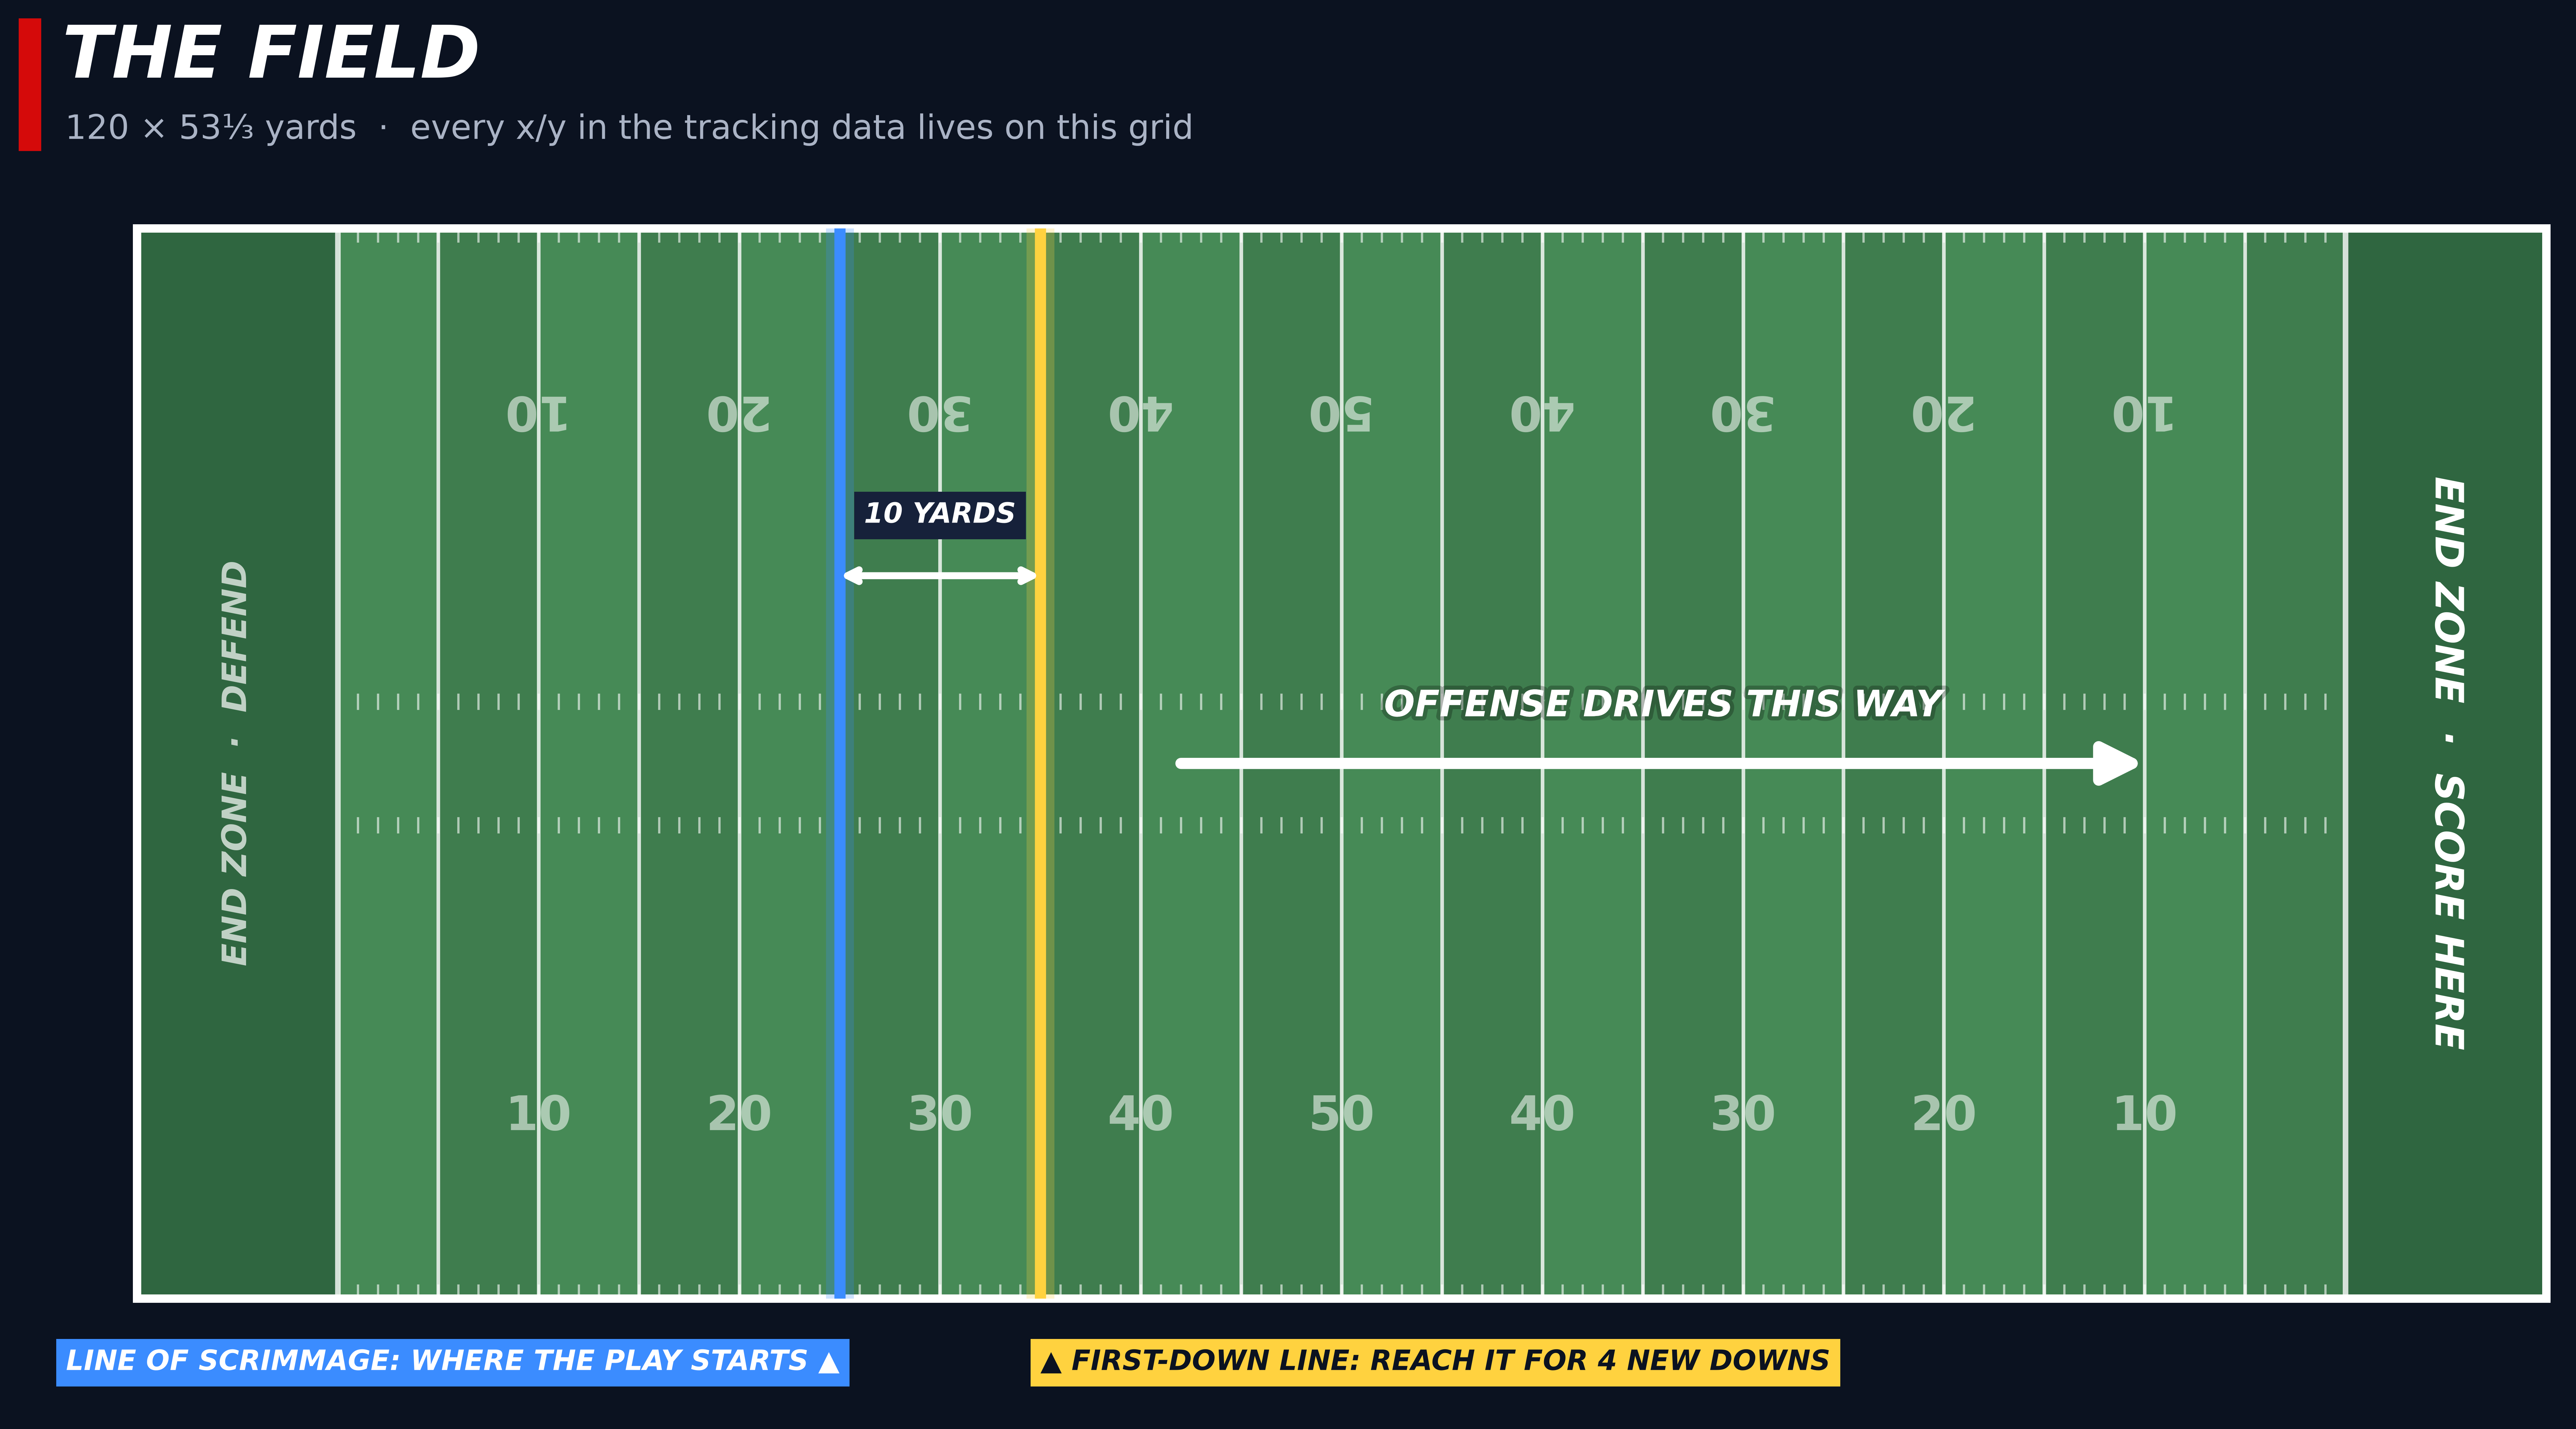

In [71]:
fig = plt.figure(figsize=(14, 7.6), facecolor=NAVY)
ax = fig.add_axes([0.03, 0.06, 0.94, 0.78])
draw_field(ax)
los, first_down = 35, 45
glow_line(ax, [los, los], [0, 53.3], LOS_BLUE)
glow_line(ax, [first_down, first_down], [0, 53.3], FIRST_DOWN_YELLOW)

# 10-yard bracket and drive direction
ax.annotate("", xy=(first_down, 36), xytext=(los, 36), zorder=4,
            arrowprops=dict(arrowstyle="<->", color="white", lw=2.5, shrinkA=0, shrinkB=0))
tag(ax, (los + first_down) / 2, 39, "10 YARDS", NAVY_2, ha="center")
ax.annotate("", xy=(100, 26.65), xytext=(52, 26.65), zorder=4,
            arrowprops=dict(arrowstyle="-|>", color="white", lw=4, mutation_scale=30, shrinkA=0, shrinkB=0),
            )
ax.text(76, 29, "OFFENSE DRIVES THIS WAY", color="white", ha="center", fontsize=13, fontweight="bold",
        fontstyle="italic", zorder=4, path_effects=[pe.withStroke(linewidth=3, foreground="#00000040")])

# End zones
ax.text(115, 26.65, "END ZONE  ·  SCORE HERE", color="white", ha="center", va="center", rotation=270,
        fontsize=14, fontweight="bold", fontstyle="italic", zorder=4)
ax.text(5, 26.65, "END ZONE  ·  DEFEND", color="white", alpha=0.7, ha="center", va="center", rotation=90,
        fontsize=12, fontweight="bold", fontstyle="italic", zorder=4)

# Line tags hang below the field, pointing up at the line they name
tag(ax, los, -3.2, "LINE OF SCRIMMAGE: WHERE THE PLAY STARTS ▲", LOS_BLUE, ha="right", clip_on=False)
tag(ax, first_down, -3.2, "▲ FIRST-DOWN LINE: REACH IT FOR 4 NEW DOWNS", FIRST_DOWN_YELLOW, NAVY, clip_on=False)
ax.set_xlim(-0.5, 120.5)
ax.set_ylim(-5.5, 53.8)
broadcast_header(fig, "THE FIELD", "120 × 53⅓ yards  ·  every x/y in the tracking data lives on this grid")
plt.show()

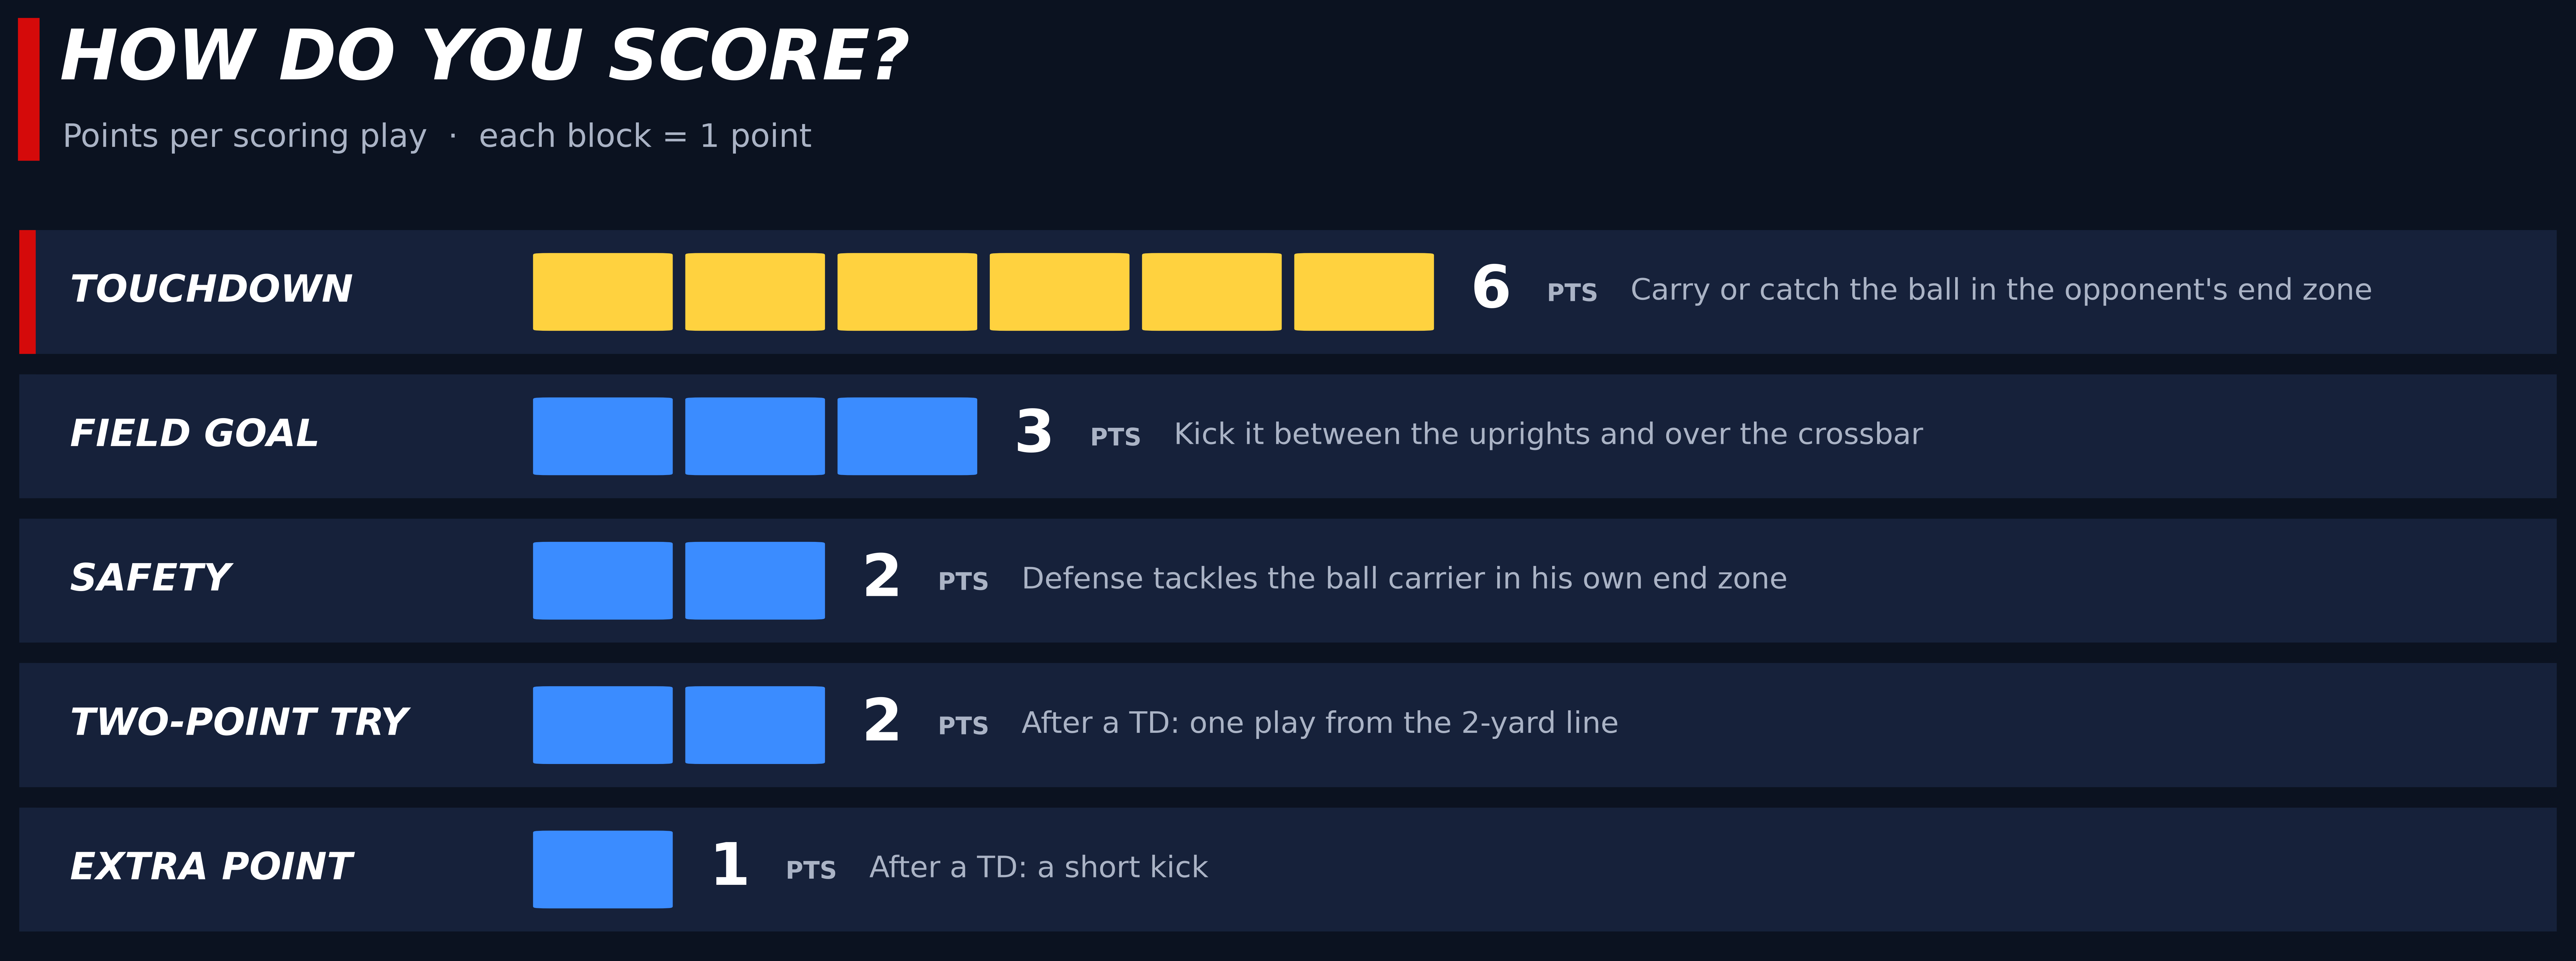

In [72]:
scores = [("TOUCHDOWN", 6, "Carry or catch the ball in the opponent's end zone"),
          ("FIELD GOAL", 3, "Kick it between the uprights and over the crossbar"),
          ("SAFETY", 2, "Defense tackles the ball carrier in his own end zone"),
          ("TWO-POINT TRY", 2, "After a TD: one play from the 2-yard line"),
          ("EXTRA POINT", 1, "After a TD: a short kick")]
BAR_X, UNIT = 0.20, 0.06           # where bars start (axes fraction) and width of one point

fig = plt.figure(figsize=(14, 5.2), facecolor=NAVY)
ax = fig.add_axes([0.03, 0.04, 0.94, 0.72])
ax.set_facecolor(NAVY)
for i, (label, pts, how) in enumerate(scores):
    y = len(scores) - 1 - i
    ax.add_patch(Rectangle((0, y - 0.42), 1, 0.84, color=NAVY_2, zorder=0))              # row panel
    ax.add_patch(Rectangle((0, y - 0.42), 0.006, 0.84, color=ESPN_RED if pts == 6 else NAVY_2, zorder=1))
    ax.text(0.02, y, label, color="white", fontsize=14, fontweight="bold", fontstyle="italic", va="center")
    for p in range(pts):                                                                  # one block per point
        ax.add_patch(FancyBboxPatch((BAR_X + p * UNIT + 0.003, y - 0.26), UNIT - 0.006, 0.52,
                                    boxstyle="round,pad=0,rounding_size=0.006",
                                    color=FIRST_DOWN_YELLOW if pts == 6 else LOS_BLUE, zorder=2))
    end = BAR_X + pts * UNIT
    ax.text(end + 0.012, y, f"{pts}", color="white", fontsize=22, fontweight="bold", va="center")
    ax.text(end + 0.042, y - 0.02, "PTS", color=SUBTLE, fontsize=9, fontweight="bold", va="center")
    ax.text(end + 0.075, y, how, color=SUBTLE, fontsize=11, fontweight="normal", va="center")
ax.set_xlim(0, 1)
ax.set_ylim(-0.5, len(scores) - 0.5)
ax.axis("off")
broadcast_header(fig, "HOW DO YOU SCORE?", "Points per scoring play  ·  each block = 1 point",
                 top=0.96, height=0.14)
plt.show()

---
### 👥 Who's on the field?
Every play is 11 vs 11, and each player has a specialised job that shapes the **body type** and **skills** scouts look for at the Combine.
The Combine data groups prospects into **five position groups** (`combine_position`), coloured below. Everyone in grey has no Combine drills in this dataset, and the white arrows show where each receiver runs on the play.

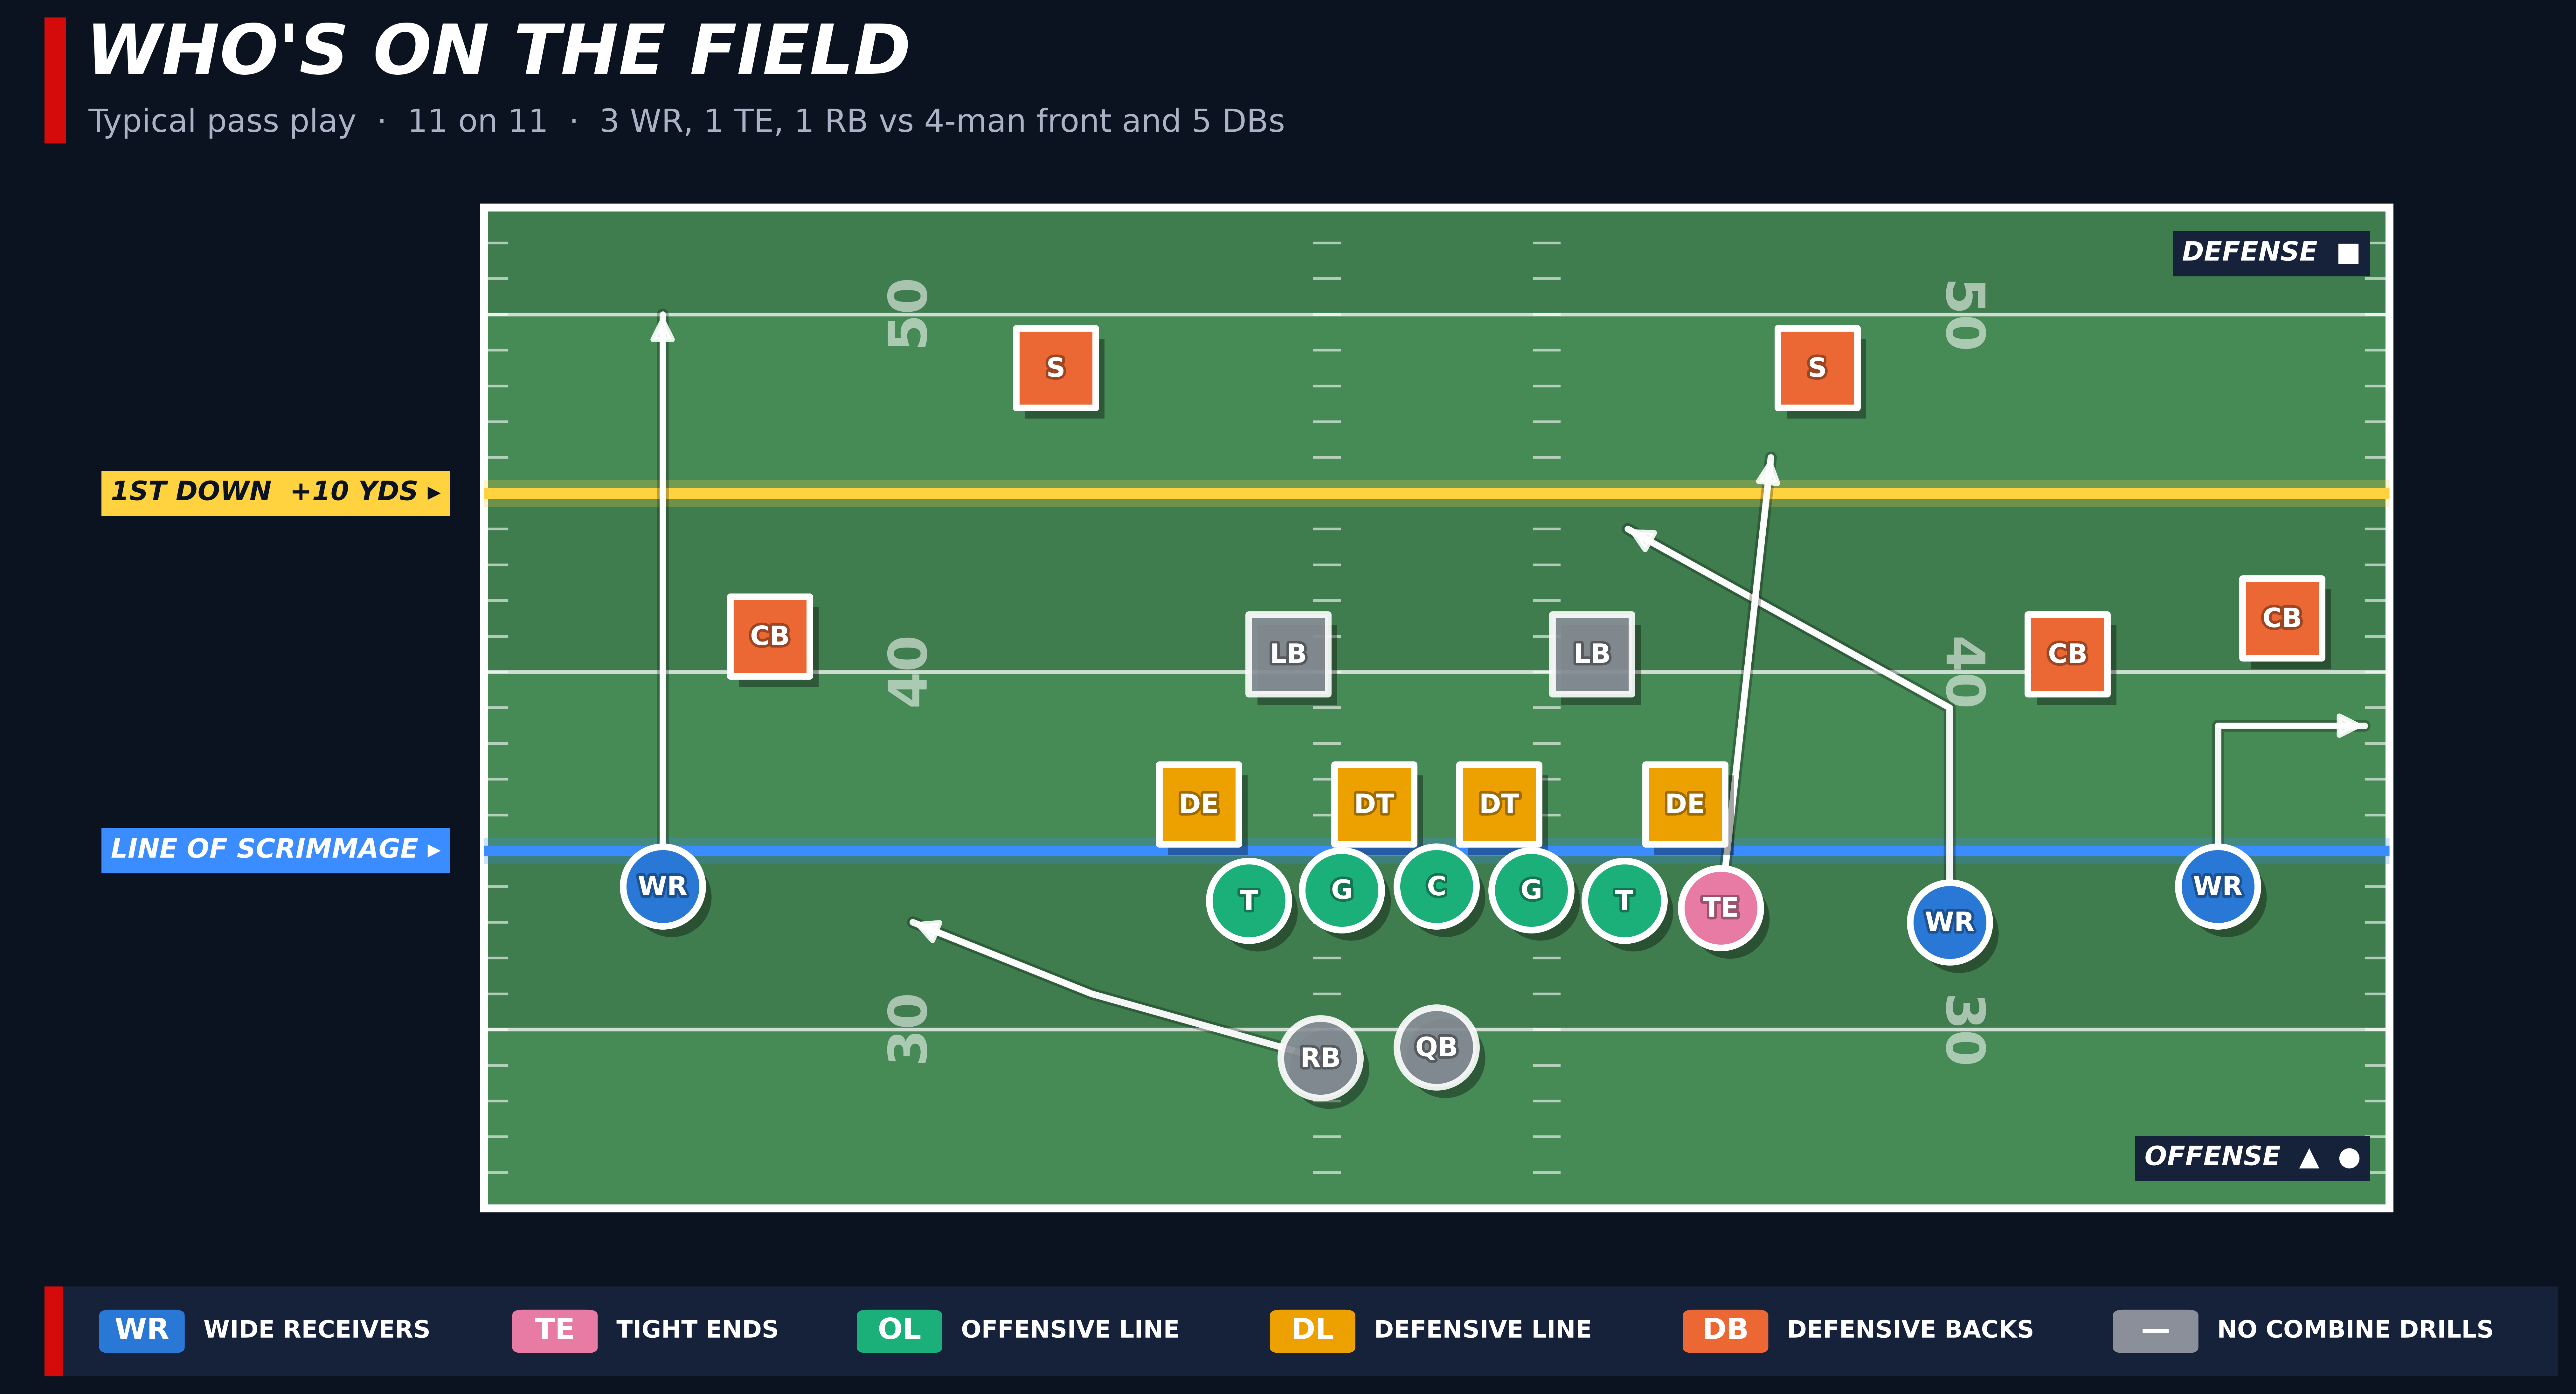

In [73]:
# (label, across-field position, yards from the line of scrimmage, group). Offense attacks upward.
OFFENSE = [
    ("C", 26.65, -1, "OL"), ("G", 24.0, -1.1, "OL"), ("G", 29.3, -1.1, "OL"), ("T", 21.4, -1.4, "OL"), ("T", 31.9, -1.4, "OL"),
    ("TE", 34.6, -1.6, "TE"), ("QB", 26.65, -5.5, None), ("RB", 23.4, -5.8, None),
    ("WR", 5, -1, "WR"), ("WR", 41, -2, "WR"), ("WR", 48.5, -1, "WR")]
DEFENSE = [
    ("DE", 20.0, 1.3, "DL"), ("DT", 24.9, 1.3, "DL"), ("DT", 28.4, 1.3, "DL"), ("DE", 33.6, 1.3, "DL"),
    ("LB", 22.5, 5.5, None), ("LB", 31, 5.5, None),
    ("CB", 8, 6, "DB"), ("CB", 44.3, 5.5, "DB"), ("CB", 50.3, 6.5, "DB"), ("S", 16, 13.5, "DB"), ("S", 37.3, 13.5, "DB")]
# Telestrator routes: (x, y) waypoints for each eligible receiver
ROUTES = [[(5, -1), (5, 15)],                                   # go
          [(41, -2), (41, 4), (32, 9)],                         # slant-in
          [(48.5, -1), (48.5, 3.5), (52.6, 3.5)],               # quick out
          [(34.6, -1.6), (36, 11)],                             # seam
          [(23.4, -5.8), (17, -4), (12, -2)]]                   # flat
Y0, Y1 = -10, 18          # visible field: 10 yards behind to 18 yards past the line of scrimmage

fig = plt.figure(figsize=(14, 7.6), facecolor=NAVY)
ax = fig.add_axes([0.02, 0.14, 0.96, 0.71])
ax.set_facecolor(NAVY)

# Turf: mowed stripes every 5 yards, sidelines, yard lines, hash marks and numbers (LOS on the offense's own 35)
for i, y in enumerate(range(Y0, Y1, 5)):
    ax.add_patch(Rectangle((0, y), 53.3, min(5, Y1 - y), color=TURF_A if i % 2 else TURF_B, zorder=0))
ax.add_patch(Rectangle((0, Y0), 53.3, Y1 - Y0, fill=False, ec="white", lw=3, zorder=1))
for y in range(Y0, Y1 + 1, 5):
    ax.plot([0, 53.3], [y, y], color="white", lw=1.4, alpha=0.75, zorder=1)
for y in range(Y0 + 1, Y1):
    for x in (0.3, 23.58, 29.73, 53.0):
        ax.plot([x - 0.35, x + 0.35], [y, y], color="white", lw=1, alpha=0.6, zorder=1)
for y in (-5, 5, 15):
    for x, rot in ((12, 90), (41.3, -90)):
        ax.text(x, y, str(35 + y), color="white", alpha=0.55, fontsize=20, fontweight="bold",
                ha="center", va="center", rotation=rot, zorder=1)

# Line of scrimmage and first-down line, broadcast style
glow_line(ax, [0, 53.3], [0, 0], LOS_BLUE)
glow_line(ax, [0, 53.3], [10, 10], FIRST_DOWN_YELLOW)

# Routes (drawn under the players)
for pts in ROUTES:
    xs, ys = zip(*pts)
    ax.plot(xs, ys, color="white", lw=2.5, alpha=0.95, zorder=3, solid_capstyle="round", solid_joinstyle="round",
            path_effects=[pe.withStroke(linewidth=4.5, foreground="#00000040")])
    ax.annotate("", xy=pts[-1], xytext=pts[-2], zorder=3,
                arrowprops=dict(arrowstyle="-|>", color="white", lw=2, alpha=0.9, mutation_scale=18,
                                shrinkA=0, shrinkB=0))

# Players: drop shadow + white ring + group colour
for team, marker in ((OFFENSE, "o"), (DEFENSE, "s")):
    for label, x, y, grp in team:
        fill = POS_COLORS.get(grp, NOT_TRACKED)
        ax.scatter(x + 0.25, y - 0.3, s=900, color="black", alpha=0.35, marker=marker, linewidth=0, zorder=4)
        ax.scatter(x, y, s=900, color=fill, marker=marker, edgecolor="white", linewidth=2.5, zorder=5,
                   alpha=1 if grp else 0.9)
        ax.text(x, y - 0.05, label, ha="center", va="center", fontsize=10, fontweight="bold",
                color="white", zorder=6, path_effects=[pe.withStroke(linewidth=2, foreground="#00000055")])

# Line tags hang in the left margin, pointing at the line they name
tag(ax, -1.2, 0.0, "LINE OF SCRIMMAGE ▸", LOS_BLUE, ha="right")
tag(ax, -1.2, 10, "1ST DOWN  +10 YDS ▸", FIRST_DOWN_YELLOW, NAVY, ha="right")
tag(ax, 52.5, -8.6, "OFFENSE  ▲  ●", NAVY_2, ha="right")
tag(ax, 52.5, 16.7, "DEFENSE  ■", NAVY_2, ha="right")
ax.set_xlim(-13, 54)
ax.set_ylim(Y0 - 0.4, Y1 + 0.4)
ax.set_aspect("equal")
ax.axis("off")
ax.set_anchor("W")

broadcast_header(fig, "WHO'S ON THE FIELD",
                 "Typical pass play  ·  11 on 11  ·  3 WR, 1 TE, 1 RB vs 4-man front and 5 DBs")

# Lower third: one chip per Combine position group
fig.add_artist(Rectangle((0.03, 0.035), 0.94, 0.06, transform=fig.transFigure, color=NAVY_2))
fig.add_artist(Rectangle((0.03, 0.035), 0.006, 0.06, transform=fig.transFigure, color=ESPN_RED))
chips = [(g, POS_COLORS[g], POS_NAMES[g]) for g in POS_COLORS] + [("—", NOT_TRACKED, "No Combine drills")]
x = 0.05
for code, color, name in chips:
    fig.add_artist(FancyBboxPatch((x, 0.05), 0.032, 0.03, boxstyle="round,pad=0,rounding_size=0.004",
                                  transform=fig.transFigure, fc=color, ec="none"))
    fig.text(x + 0.016, 0.065, code, color="white", fontsize=11, fontweight="bold", ha="center", va="center")
    fig.text(x + 0.039, 0.065, name.upper(), color="white", fontsize=9, fontweight="bold", va="center")
    x += 0.065 + 0.0064 * len(name)
plt.show()

| Group | Side | Who's in it | What they do | Combine profile |
| :--- | :--- | :--- | :--- | :--- |
| **OL** – Offensive Line | Offense | Tackles (T), Guards (G), Center (C) | Five big blockers who protect the QB and open running lanes. The center snaps the ball. | Heaviest players; judged on strength, short area quickness and footwork |
| **TE** – Tight End | Offense | Tight Ends (and the odd FB) | Hybrid of lineman and receiver: blocks at the line or releases to catch passes. | Big *and* fast; tested on both blocking and route drills |
| **WR** – Wide Receiver | Offense | Wide Receivers | Run routes and catch passes; score many of the touchdowns. | Speed, explosiveness, clean cuts and hands |
| **DL** – Defensive Line | Defense | Defensive Ends (DE), Defensive Tackles (DT), Nose Tackles (NT), edge-rushing Outside Linebackers (OLB) | Beat blocks to stop the run and pressure the QB. Edge players sometimes drop into coverage. | Power, burst off the snap and bend around blockers |
| **DB** – Defensive Back | Defense | Cornerbacks (CB), Free & Strong Safeties (FS/SS) | Cover receivers and are the last line of defense. | Fastest defenders; backpedal, hip turns and breaking on the ball |

*Not in the Combine data:* Quarterbacks (QB), Running Backs (RB), most off-ball Linebackers (LB) and Special Teams (kicker, punter, long snapper, returners). You'll see them in game tracking, but they have no Combine drills here.

---
### ⏱️ Combine drills

Every year in late February / early March, ~300 of the top college prospects travel to Indianapolis for the **NFL Scouting Combine**, where they run the same set of drills in front of all 32 teams.

There are 56 total drills grouped by the positions that runs them, with reasoning behind why each one matters on game day.

👉 **Click a position group to expand its drills.**

<details open>
<summary><b>🏃 Athletic testing: all positions</b> · 6 drills</summary>

| Drill | Category | Why it matters in games | GIF |
| :--- | :--- | :--- | :---: |
| 40-Yard Dash | Timing & Speed | Pure straight-line speed: running away from (or chasing down) anyone in the open field. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/FORTY_YARD_DASH_video.gif" width="300" alt="40-Yard Dash"> |
| Vertical Jump | Explosiveness | Lower-body explosiveness: winning jump balls, and power off the snap. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/VERTICAL_JUMP_video.gif" width="300" alt="Vertical Jump"> |
| Broad Jump | Explosiveness | Horizontal explosiveness: the first-step burst off the line and out of breaks. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/BROAD_JUMP_video.gif" width="300" alt="Broad Jump"> |
| Bench Press (225 lb) | Strength | Upper-body strength endurance: holding blocks and shedding blockers in the trenches. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/BENCH_PRESS_video.gif" width="300" alt="Bench Press (225 lb)"> |
| 3-Cone Drill | Agility & COD | Bending around tight corners at speed: rounding routes, chasing the QB, closing on the ball. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/THREE_CONE_DRILL_video.gif" width="300" alt="3-Cone Drill"> |
| 20-Yard Short Shuttle | Lateral Quickness | Stop, plant and go the other way: the change of direction behind every cut and reaction. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/SHORT_SHUTTLE_video.gif" width="300" alt="20-Yard Short Shuttle"> |

</details>

<details>
<summary><b>🧱 Offensive Line (OL)</b> · 7 drills</summary>

| Drill | Category | Why it matters in games | GIF |
| :--- | :--- | :--- | :---: |
| OL Pull Drill: Fold Block Right | Offensive Line | Short, quick pull around a teammate: sealing the hole on inside runs. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/OL_PULL_DRILL_FOLD_BLOCK_RIGHT.gif" width="300" alt="OL Pull Drill: Fold Block Right"> |
| OL Pull Drill: Deep Short Pull Left | Offensive Line | Leaving the line at an angle and finding a target: lead blocking on gap runs. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT.gif" width="300" alt="OL Pull Drill: Deep Short Pull Left"> |
| OL Pull Drill: Long Pull Right | Offensive Line | Running laterally in space: leading outside runs and sweeps. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/OL_PULL_DRILL_LONG_PULL_RIGHT.gif" width="300" alt="OL Pull Drill: Long Pull Right"> |
| Pass Protection Mirror Drill | Offensive Line | Sliding to shadow a rusher without crossing feet: keeping the QB clean. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/PASS_PRO_MIRROR_DRILL.gif" width="300" alt="Pass Protection Mirror Drill"> |
| Screen Drill | Offensive Line | Releasing downfield and blocking in space: springing screen passes. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/SCREEN_DRILL.gif" width="300" alt="Screen Drill"> |
| Pass Rush Drop | Offensive Line / Pass Pro | Quick kick-slide into a pass set: getting depth before the edge rusher arrives. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/PASS_RUSH_DROP.gif" width="300" alt="Pass Rush Drop"> |
| 5-Yard Wave Drill (Slide & Shuffle) | Offensive Line | Reacting to direction changes while staying balanced: handling stunts and counters. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE.gif" width="300" alt="5-Yard Wave Drill (Slide & Shuffle)"> |

</details>

<details>
<summary><b>🎯 Tight Ends (TE)</b> · 7 drills</summary>

| Drill | Category | Why it matters in games | GIF |
| :--- | :--- | :--- | :---: |
| Block Explosion Drill | TE Blocking | Firing out of a stance with power: winning blocks on run plays. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/BLOCK_EXPLOSION.gif" width="300" alt="Block Explosion Drill"> |
| Corner Route | Route Tree | Breaking to the sideline at depth: stretching zones vertically. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/CORNER_ROUTE.gif" width="300" alt="Corner Route"> |
| Flat Route (Left) | Route Tree | Releasing quickly to the flat: easy yards and play-action answers. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/FLAT_ROUTE_LEFT.gif" width="300" alt="Flat Route (Left)"> |
| Hook Route (Right) | Route Tree | Settling in a zone gap and turning to the QB: moving the chains on 3rd down. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/HOOK_ROUTE_RIGHT.gif" width="300" alt="Hook Route (Right)"> |
| End Zone Fade (Right) | Route Tree | Using size near the boundary: red-zone touchdowns. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/END_ZONE_FADE_RIGHT.gif" width="300" alt="End Zone Fade (Right)"> |
| In Route (Left) | Route Tree | Sharp inside break in traffic: catching in front of linebackers. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/IN_ROUTE_LEFT.gif" width="300" alt="In Route (Left)"> |
| Wheel Route (Left) | Route Tree | Turning upfield from the flat: exploiting slower linebackers in coverage. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/WHEEL_ROUTE_LEFT.gif" width="300" alt="Wheel Route (Left)"> |

</details>

<details>
<summary><b>🙌 Wide Receivers (WR)</b> · 14 drills</summary>

| Drill | Category | Why it matters in games | GIF |
| :--- | :--- | :--- | :---: |
| Gauntlet Catching Drill *(WR, TE, DB)* | Receiver / TE / RB | Catching at full speed with eyes on the ball: crossing routes for WR/TE, turning breakups into interceptions for DBs. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/GAUNTLET_DRILL.gif" width="300" alt="Gauntlet Catching Drill"> |
| Over the Shoulder Adjustment *(WR, TE)* | Receiver / TE | Tracking a deep ball and adjusting late: the catch on long and seam throws. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/OVER_SHOULDER_ADJUST.gif" width="300" alt="Over the Shoulder Adjustment"> |
| Red Zone Fade (Right) | Route Tree | Separating in a tight space near the sideline: scoring in the red zone. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/RED_ZONE_FADE_RIGHT.gif" width="300" alt="Red Zone Fade (Right)"> |
| Post-Corner Route (Right) | Route Tree | Selling the post, then snapping to the corner: beating safeties deep. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/POST_CORNER_ROUTE_RIGHT.gif" width="300" alt="Post-Corner Route (Right)"> |
| Post-Corner Route (Left) | Route Tree | Same double move to the other side: the route works from either alignment. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/POST_CORNER_ROUTE_LEFT.gif" width="300" alt="Post-Corner Route (Left)"> |
| Go Route (Right) | Route Tree | Top-end speed downfield: forcing defenders to back off and respect the deep ball. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/GO_ROUTE_RIGHT.gif" width="300" alt="Go Route (Right)"> |
| Circus Route (Left) | Route Tree | Body control on awkward catches: turning broken plays into completions. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/CIRCUS_ROUTE_LEFT.gif" width="300" alt="Circus Route (Left)"> |
| Slant Route (Left) | Route Tree | A fast, sharp break inside: the quick throw that beats blitzes and tight coverage. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/SLANT_ROUTE_LEFT.gif" width="300" alt="Slant Route (Left)"> |
| Speed Out Route (Left) | Route Tree | Cutting to the sideline without slowing down: separation on timing throws. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/SPEED_OUT_ROUTE_LEFT.gif" width="300" alt="Speed Out Route (Left)"> |
| Curl Route (Right) | Route Tree | Selling deep, then stopping and turning back: winning against defenders who play off. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/CURL_ROUTE_RIGHT.gif" width="300" alt="Curl Route (Right)"> |
| Dagger Route (Left) | Route Tree | Breaking inside at depth: attacking the middle behind the linebackers. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/DAGGER_ROUTE_LEFT.gif" width="300" alt="Dagger Route (Left)"> |
| Slot Strike Route (Left) | Route Tree | Quick release and break from the slot: winning fast against nickel corners. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/SLOT_STRIKE_ROUTE_LEFT.gif" width="300" alt="Slot Strike Route (Left)"> |
| Comeback Route (Right) | Route Tree | Braking hard after a vertical stem: getting open when the DB is running with you. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/COMEBACK_ROUTE_RIGHT.gif" width="300" alt="Comeback Route (Right)"> |
| Slot Sail Route (Right) | Route Tree | Climbing and bending to the sideline from the slot: attacking zone holes. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/SLOT_SAIL_ROUTE_RIGHT.gif" width="300" alt="Slot Sail Route (Right)"> |

</details>

<details>
<summary><b>💥 Defensive Line (DL)</b> · 14 drills</summary>

| Drill | Category | Why it matters in games | GIF |
| :--- | :--- | :--- | :---: |
| Pass Rush Drill | Defensive Line / EDGE | Beating a blocker with a rip or swim and finishing: pressures and sacks. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/PASS_RUSH_DRILL.gif" width="300" alt="Pass Rush Drill"> |
| Run & Club Drill | Pass Rush | Winning the edge with a club move at speed: getting past tackles. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/RUN_AND_CLUB_DRILL.gif" width="300" alt="Run & Club Drill"> |
| Run the Hoop Drill | Pass Rush / Bend | Bending around a tight circle while leaning in: turning the corner to the QB. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/RUN_THE_HOOP_DRILL.gif" width="300" alt="Run the Hoop Drill"> |
| Short Zone Break: Forward | Defensive Line / Coverage Drop | Driving downhill out of a drop: stopping short passes underneath. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/SHORT_ZONE_BREAK_FORWARD.gif" width="300" alt="Short Zone Break: Forward"> |
| Short Zone Break: Flat/Wheel | Defensive Line / Coverage Drop | Turning to run with a back out of the flat: covering wheel routes. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/SHORT_ZONE_BREAK_FLAT_WHEEL.gif" width="300" alt="Short Zone Break: Flat/Wheel"> |
| Short Zone Break: Inside | Defensive Line / Coverage Drop | Breaking back inside from a drop: closing on slants and crossers. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/SHORT_ZONE_BREAK_INSIDE.gif" width="300" alt="Short Zone Break: Inside"> |
| Short Zone Breaks (General) | Defensive Line / Coverage Drop | Dropping into a zone and breaking on the throw: edge rushers asked to cover. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/SHORT_ZONE_BREAKS.gif" width="300" alt="Short Zone Breaks (General)"> |
| Front Start Wave & Lateral Reaction | Defensive Line / Agility | Reacting to a direction change from a stance: chasing runs and scrambling QBs. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION.gif" width="300" alt="Front Start Wave & Lateral Reaction"> |
| Backpedal & React | Defensive Line / Coverage Drop | Dropping back and breaking on the ball: edge players dropping into coverage. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/BACK_PEDAL_AND_REACT.gif" width="300" alt="Backpedal & React"> |
| Body Control Drill | Footwork & Balance | Changing direction with a low centre of gravity: shedding blocks and redirecting. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/BODY_CONTROL_DRILL.gif" width="300" alt="Body Control Drill"> |
| Four Bag Agility Drill | Bag Agility | Quick, controlled feet through traffic: stepping over bodies in the trenches. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/FOUR_BAG_AGILITY_DRILL.gif" width="300" alt="Four Bag Agility Drill"> |
| Four Bag Shuffle Drill | Bag Agility | Lateral shuffle while staying square: flowing to the ball on runs. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/FOUR_BAG_SHUFFLE_DRILL.gif" width="300" alt="Four Bag Shuffle Drill"> |
| Shuffle, Sprint & COD Drill | Agility & Acceleration | Shuffle then burst: pursuing plays that bounce outside. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/SHUFFLE_SPRINT_AND_COD_DRILL.gif" width="300" alt="Shuffle, Sprint & COD Drill"> |
| Wave Drill | Reactive Agility | Reactive changes of direction: tracking the ball carrier. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/WAVE_DRILL.gif" width="300" alt="Wave Drill"> |

</details>

<details>
<summary><b>🛡️ Defensive Backs (DB)</b> · 7 drills</summary>

| Drill | Category | Why it matters in games | GIF |
| :--- | :--- | :--- | :---: |
| Backpedal & 45° Transition | Secondary | Opening the hips from a backpedal: carrying receivers who go deep. *(2024 reps are truncated)* | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION.gif" width="300" alt="Backpedal & 45° Transition"> |
| Backpedal & 90° Break to Ball | Secondary | Backpedal, plant, drive sideways: breaking on out routes. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL.gif" width="300" alt="Backpedal & 90° Break to Ball"> |
| Teryl Austin DB Drill #1 | Secondary | Backpedal and break at an angle on cue: reading the QB and closing on the ball. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/TERYL_AUSTIN_DRILL_1.gif" width="300" alt="Teryl Austin DB Drill #1"> |
| Teryl Austin DB Drill #2 | Secondary | Backpedal, turn and run: staying with receivers who stem vertically. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/TERYL_AUSTIN_DRILL_2.gif" width="300" alt="Teryl Austin DB Drill #2"> |
| Box Drill | Change of Direction | Sprint, shuffle and backpedal around a square: every movement a DB uses in one rep. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/BOX_DRILL.gif" width="300" alt="Box Drill"> |
| W-Drill | Backpedal & Plant | Repeated backpedal-and-drive zig-zags: keeping the pedal smooth while reacting to the route. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/W_DRILL.gif" width="300" alt="W-Drill"> |
| Line Drill | Speed & Conditioning | Straight backpedal-to-sprint transitions: speed turning to run with a receiver. | <img src="https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/LINE_DRILL.gif" width="300" alt="Line Drill"> |

</details>

---
## 3 · Meet the rookies
The dataset follows **one cohort**: every player from the 2023, 2024 and 2025 draft classes who was tracked at the Combine, plus how their NFL careers went.

In [74]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl


def find_data_dir() -> Path:
    """Kaggle input folder, or a local copy (set NFL_DATA to override)."""
    if os.environ.get("NFL_DATA"):
        return Path(os.environ["NFL_DATA"])
    for root in [Path("/kaggle/input"), Path("../data/raw"), Path("data/raw")]:
        hits = sorted(root.glob("**/combine_results.csv")) if root.exists() else []
        if hits:
            return hits[0].parent
    raise FileNotFoundError("Add the nfl-big-data-bowl-2027 competition data to this notebook.")


def read(name: str) -> pl.DataFrame:
    return pl.read_csv(DATA / f"{name}.csv", null_values="NA", infer_schema_length=100_000)


DATA = find_data_dir()
players = read("players")
combine = read("combine_results")
career = read("player_career_successes")

# One row per rookie: bio + draft info, Combine results, and NFL career outcomes
cohort = (players.join(combine.select(pl.exclude("draft_year")), on="nfl_id")
          .join(career, on="nfl_id", how="left")
          .rename({"combine_position": "pos"}))
POS_ORDER = ["WR", "TE", "OL", "DL", "DB"]
print(f"Data folder: {DATA}  ·  {cohort.height} rookies")

Data folder: ../data/raw/nfl-big-data-bowl-2027  ·  510 rookies


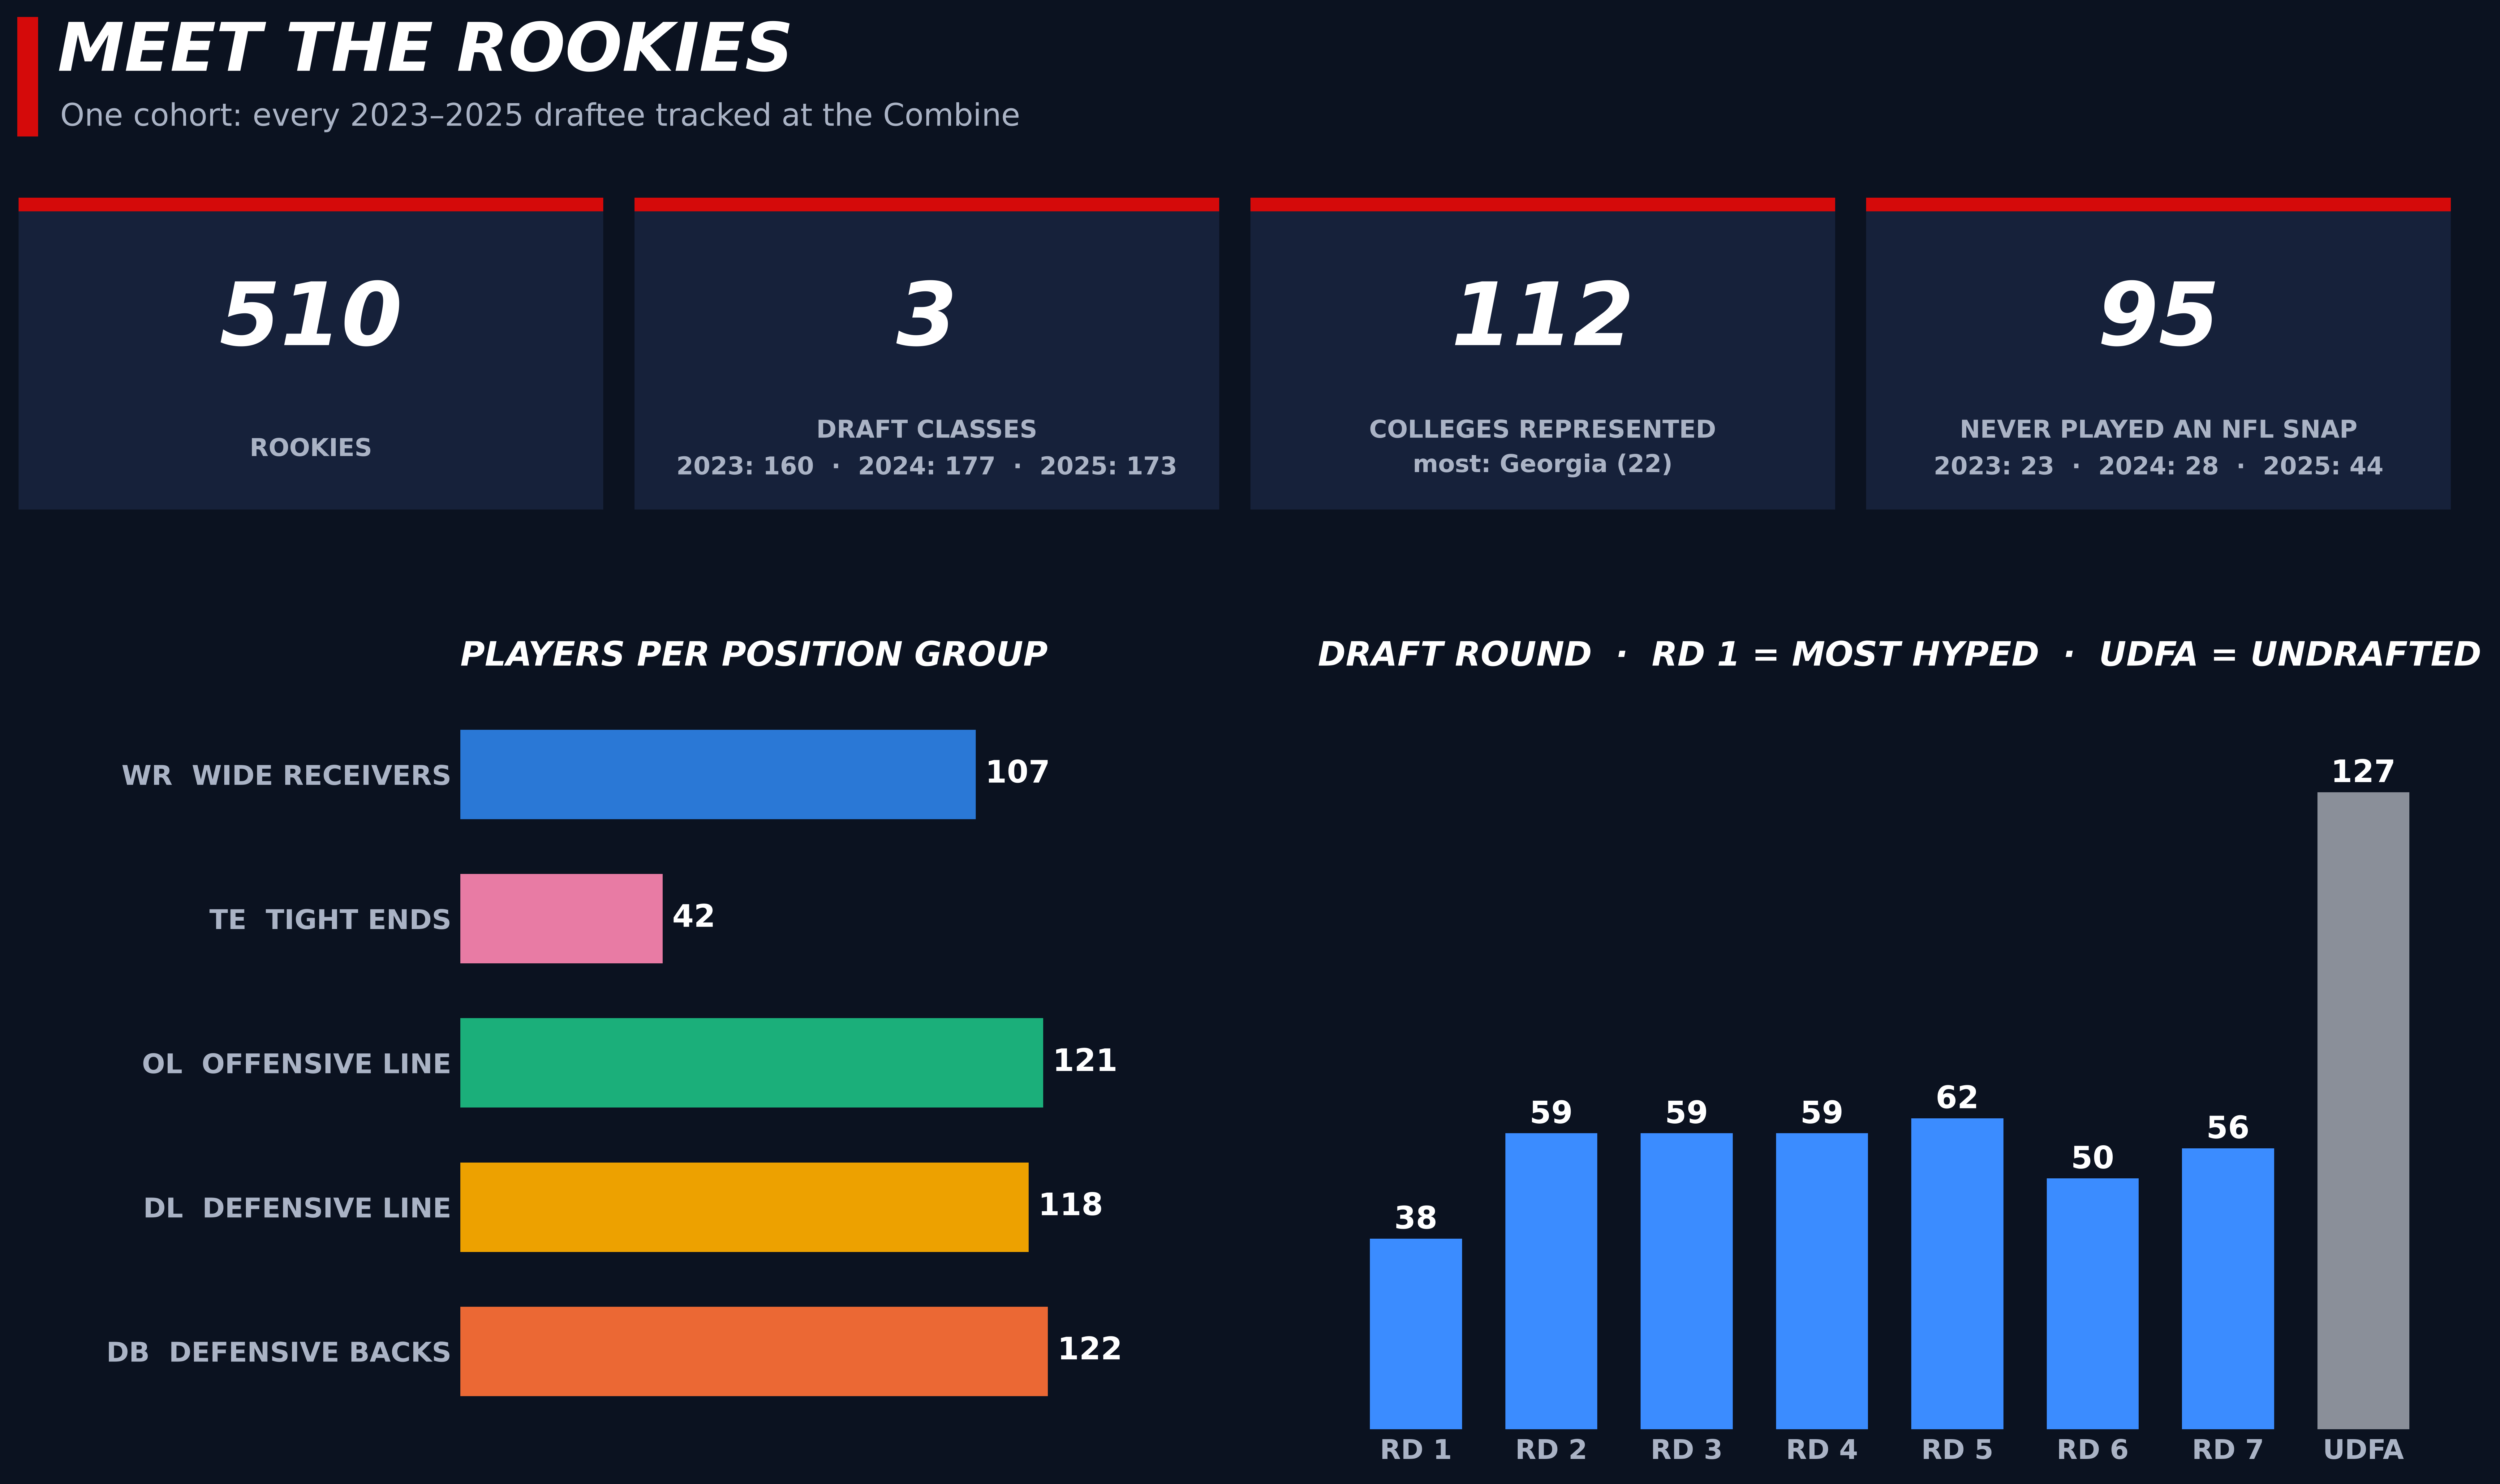

In [75]:
per_class = cohort.group_by("draft_year").len().sort("draft_year")
top_college, top_college_n = cohort["college_name"].value_counts(sort=True).row(0)
# "Never played" = zero offensive, defensive and special-teams snaps (some dressed for games but never got on the field)
no_snaps = cohort.filter(pl.sum_horizontal(pl.col("career_offensive_snaps", "career_defensive_snaps",
                                                  "career_special_teams_snaps").fill_null(0)) == 0)
tiles = [(f"{cohort.height}", "ROOKIES"),
         ("3", "DRAFT CLASSES\n" + "  ·  ".join(f"{y}: {n}" for y, n in per_class.iter_rows())),
         (f"{cohort['college_name'].n_unique()}", f"COLLEGES REPRESENTED\nmost: {top_college} ({top_college_n})"),
         (f"{no_snaps.height}", "NEVER PLAYED AN NFL SNAP\n" + "  ·  ".join(
             f"{y}: {n}" for y, n in no_snaps.group_by("draft_year").len().sort("draft_year").iter_rows()))]

fig = plt.figure(figsize=(14, 8.4), facecolor=NAVY)
broadcast_header(fig, "MEET THE ROOKIES", "One cohort: every 2023–2025 draftee tracked at the Combine",
                 top=0.975, height=0.075)

# Stat tiles
for i, (big, small) in enumerate(tiles):
    ax = fig.add_axes([0.03 + i * 0.237, 0.66, 0.225, 0.2])
    ax.add_patch(Rectangle((0, 0), 1, 1, color=NAVY_2, transform=ax.transAxes))
    ax.add_patch(Rectangle((0, 0.96), 1, 0.04, color=ESPN_RED, transform=ax.transAxes))
    ax.text(0.5, 0.6, big, ha="center", va="center", fontsize=34, fontweight="bold", fontstyle="italic",
            color="white", transform=ax.transAxes)
    ax.text(0.5, 0.2, small, ha="center", va="center", fontsize=9.5, fontweight="bold", color=SUBTLE,
            linespacing=1.5, transform=ax.transAxes)
    ax.axis("off")


def panel(rect, title):
    ax = fig.add_axes(rect)
    ax.set_facecolor(NAVY)
    ax.set_title(title, loc="left", color="white", fontsize=13, fontweight="bold", fontstyle="italic", pad=12)
    for side in ax.spines.values():
        side.set_visible(False)
    ax.tick_params(colors=SUBTLE, length=0, labelsize=10.5)
    return ax


# Players per position group
a1 = panel([0.2, 0.07, 0.26, 0.47], "PLAYERS PER POSITION GROUP")
counts = cohort.group_by("pos").len().to_pandas().set_index("pos").loc[POS_ORDER[::-1]]
a1.barh(range(5), counts["len"], color=[POS_COLORS[p] for p in counts.index], height=0.62)
for y, v in enumerate(counts["len"]):
    a1.text(v + 2, y, v, va="center", color="white", fontsize=12, fontweight="bold")
a1.set_yticks(range(5), [f"{p}  {POS_NAMES[p].upper()}" for p in counts.index], fontweight="bold")
a1.set_xticks([])
a1.set_xlim(0, counts["len"].max() * 1.15)

# Draft round
a2 = panel([0.53, 0.07, 0.44, 0.47], "DRAFT ROUND  ·  RD 1 = MOST HYPED  ·  UDFA = UNDRAFTED")
rounds = (cohort.with_columns(r=pl.col("draft_round").cast(pl.String).fill_null("UDFA"))
          .group_by("r").len().to_pandas().set_index("r").reindex([*map(str, range(1, 8)), "UDFA"]).fillna(0))
a2.bar(range(len(rounds)), rounds["len"], color=[LOS_BLUE] * 7 + [NOT_TRACKED], width=0.68)
for x, v in enumerate(rounds["len"]):
    a2.text(x, v + 2, int(v), ha="center", color="white", fontsize=12, fontweight="bold")
a2.set_xticks(range(len(rounds)), [f"RD {r}" if r != "UDFA" else r for r in rounds.index], fontweight="bold")
a2.set_yticks([])
a2.set_ylim(0, rounds["len"].max() * 1.15)
plt.show()

### Built for the job
Each dot is one rookie, measured at the Combine. Height and weight sort players into **three body types** almost perfectly:

- **Skill** (WR + DB): about 6'0", 195 lb
- **Hybrid** (TE + edge rushers): about 6'4", 250 lb
- **Big** (OL + interior DL): about 6'4", 310 lb

Inside a body type, though, a tape measure can't tell positions apart: a receiver and a cornerback are built the same. Adding hand size, arm length, wingspan, the stopwatch drills or the NGS scores doesn't fix that either. **Telling them apart is what the drill tracking data is for.**

> 💡 The `DL` group mixes two body types: edge rushers (DE/OLB, ~258 lb) and interior linemen (DT/NT, ~307 lb). Use `nfl_position` from `players.csv` to split them before modelling.

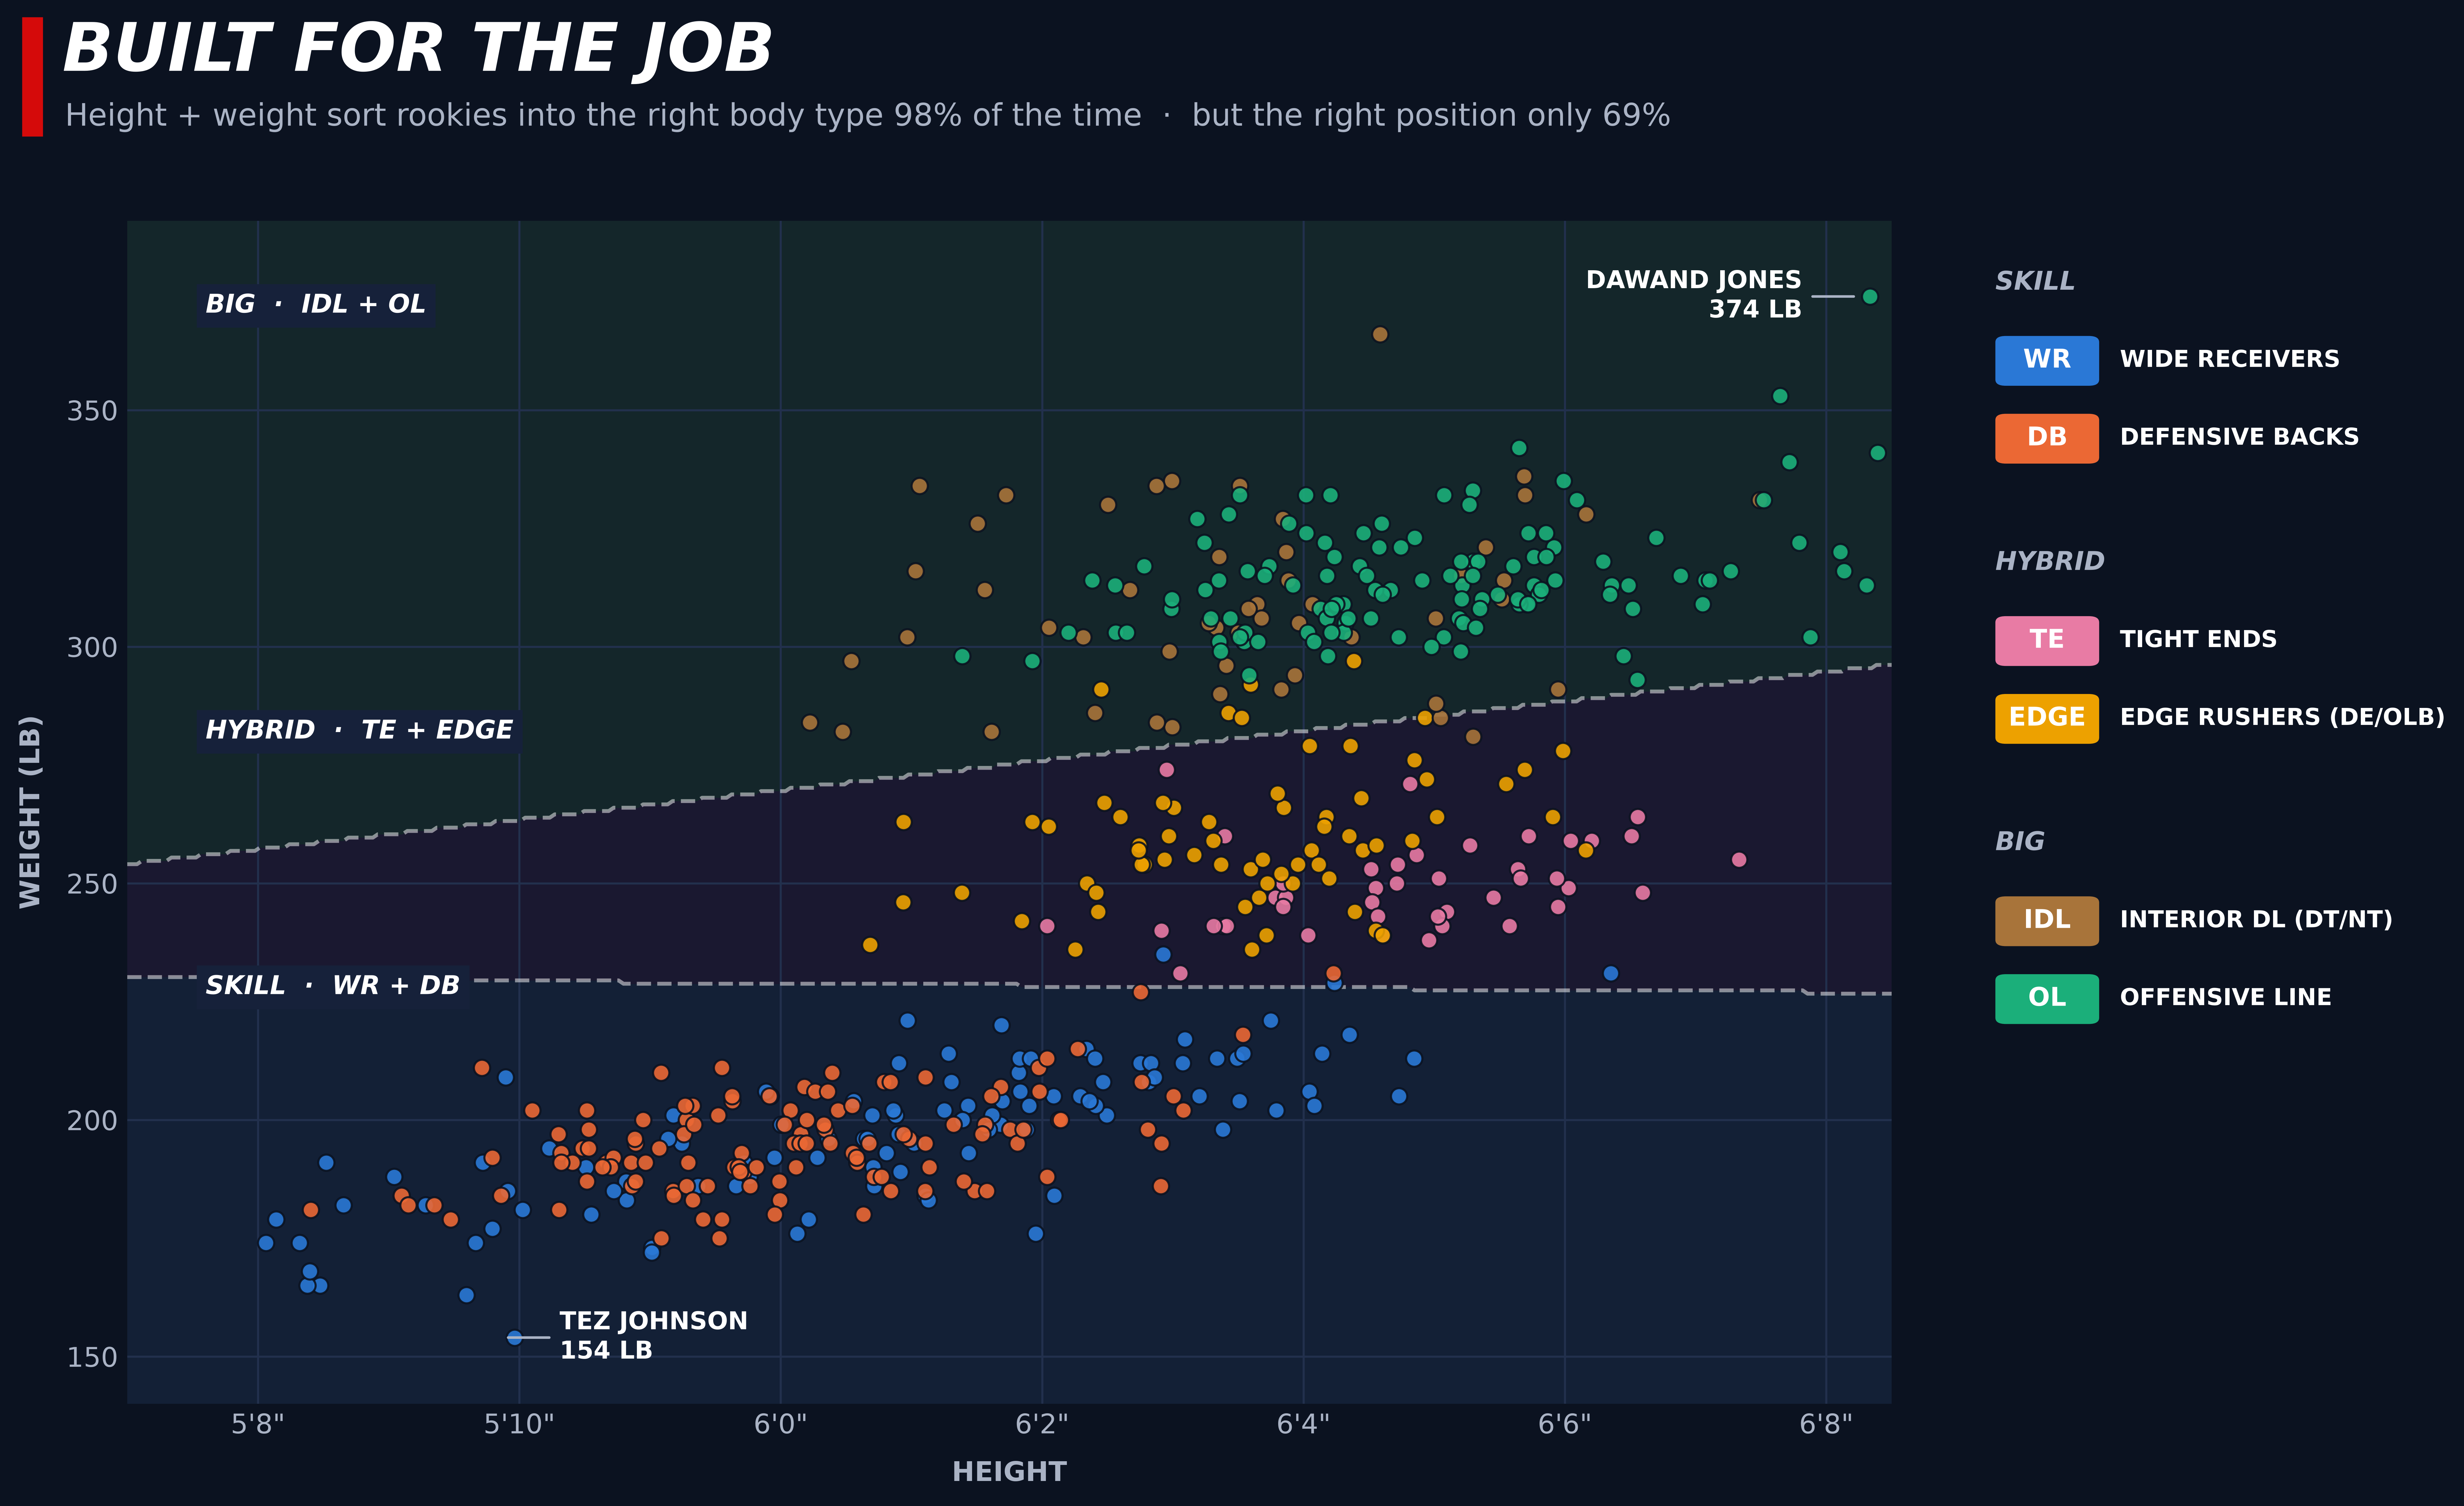

In [76]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Split the DL group by NFL position: edge rushers and interior linemen have very different bodies
cb = cohort.select("display_name", "pos", "nfl_position", "combine_height", "combine_weight").to_pandas()
cb["group"] = cb.pos.where(cb.pos != "DL", np.where(cb.nfl_position.isin(["DE", "OLB"]), "EDGE", "IDL"))
GROUP_COLORS = {"WR": POS_COLORS["WR"], "DB": POS_COLORS["DB"], "TE": POS_COLORS["TE"],
                "EDGE": POS_COLORS["DL"], "IDL": "#a8743a", "OL": POS_COLORS["OL"]}
GROUP_NAMES = {"WR": "Wide receivers", "DB": "Defensive backs", "TE": "Tight ends",
               "EDGE": "Edge rushers (DE/OLB)", "IDL": "Interior DL (DT/NT)", "OL": "Offensive line"}
BODY_TYPES = {"SKILL": ["WR", "DB"], "HYBRID": ["TE", "EDGE"], "BIG": ["IDL", "OL"]}
cb["body"] = cb.group.map({g: b for b, gs in BODY_TYPES.items() for g in gs})

# How well do height + weight alone sort players? (5-fold cross-validated linear classifier)
X = cb[["combine_height", "combine_weight"]]
cv = StratifiedKFold(5, shuffle=True, random_state=0)
acc_body = cross_val_score(LinearDiscriminantAnalysis(), X, cb.body, cv=cv).mean()
acc_pos = cross_val_score(LinearDiscriminantAnalysis(), X, cb.pos, cv=cv).mean()

fig = plt.figure(figsize=(14, 8.4), facecolor=NAVY)
broadcast_header(fig, "BUILT FOR THE JOB",
                 f"Height + weight sort rookies into the right body type {acc_body:.0%} of the time  ·  "
                 f"but the right position only {acc_pos:.0%}", top=0.97, height=0.075)
ax = fig.add_axes([0.07, 0.08, 0.68, 0.76])
ax.set_facecolor(NAVY)
for side in ax.spines.values():
    side.set_visible(False)
ax.grid(color="#22304d", lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=SUBTLE, length=0, labelsize=10.5)

# Body-type zones: shade the region where the classifier would call each body type
lda = LinearDiscriminantAnalysis().fit(X.values, cb.body)
hh, ww = np.meshgrid(np.linspace(67, 82, 400), np.linspace(140, 420, 400))
zone = pd.Series(lda.predict(np.c_[hh.ravel(), ww.ravel()])).map({b: i for i, b in enumerate(BODY_TYPES)})
zone = zone.values.reshape(hh.shape)
ax.contourf(hh, ww, zone, levels=[-0.5, 0.5, 1.5, 2.5], colors=["#132036", "#1a1830", "#14262a"], zorder=0)
ax.contour(hh, ww, zone, levels=[0.5, 1.5], colors="white", alpha=0.5, linewidths=1.5,
           linestyles="dashed", zorder=1)
LABEL_AT = {"SKILL": (67.6, 228), "HYBRID": (67.6, 282), "BIG": (67.6, 372)}
for body, groups in BODY_TYPES.items():
    tag(ax, *LABEL_AT[body], f"{body}  ·  {' + '.join(groups)}", NAVY_2)

rng = np.random.default_rng(7)
for g, color in GROUP_COLORS.items():
    d = cb[cb.group == g]
    ax.scatter(d.combine_height + rng.uniform(-0.12, 0.12, len(d)), d.combine_weight, s=40, color=color,
               alpha=0.9, edgecolor=NAVY, linewidth=0.8, zorder=3)

# Call out the heaviest (label to the left) and lightest (label to the right) rookie
for (_, r), dx in zip(pd.concat([cb.nlargest(1, "combine_weight"), cb.nsmallest(1, "combine_weight")]).iterrows(),
                      (-22, 22)):
    ax.annotate(f"{r.display_name.upper()}\n{r.combine_weight:.0f} LB", (r.combine_height, r.combine_weight),
                xytext=(dx, 0), textcoords="offset points", fontsize=9.5, fontweight="bold", color="white",
                ha="right" if dx < 0 else "left", va="center", zorder=5,
                arrowprops=dict(arrowstyle="-", color=SUBTLE))
ticks = range(68, 82, 2)
ax.set_xticks(ticks, [f"{t // 12}'{t % 12}\"" for t in ticks])
ax.set_xlim(67, 80.5)
ax.set_ylim(140, 390)
ax.set_xlabel("HEIGHT", color=SUBTLE, fontweight="bold", labelpad=8)
ax.set_ylabel("WEIGHT (LB)", color=SUBTLE, fontweight="bold", labelpad=8)

# Legend as a broadcast side panel, grouped by body type
y = 0.8
for body, groups in BODY_TYPES.items():
    fig.text(0.79, y, body, color=SUBTLE, fontsize=10, fontweight="bold", fontstyle="italic", va="center")
    y -= 0.05
    for g in groups:
        fig.add_artist(FancyBboxPatch((0.79, y - 0.016), 0.04, 0.032, boxstyle="round,pad=0,rounding_size=0.004",
                                      transform=fig.transFigure, fc=GROUP_COLORS[g], ec="none"))
        fig.text(0.81, y, g, color="white", fontsize=10, fontweight="bold", ha="center", va="center")
        fig.text(0.838, y, GROUP_NAMES[g].upper(), color="white", fontsize=9, fontweight="bold", va="center")
        y -= 0.05
    y -= 0.03
plt.show()

### 🏁 How fast does each position run?

Every position group lines up for a 40-yard dash. Each runner is the group's **median player** (each player's best attempt), replayed from the 10 Hz Combine tracking. 

> ⚠️ **Tracking starts a little late on most reps**, so tracked 40 times run about 0.3 s slower than the official `forty` in `combine_results.csv`, and a few reps are off by much more. The order of the groups holds, but don't compare tracked and official times directly. For clean speed numbers, time from the 10-yard mark onwards or use `forty - ten_yd_split`.

In [77]:
import plotly.graph_objects as go

# 40-yard dash tracking: seconds and yards since tracking started, per rep
forty = (read("combine_tracking")
         .filter((pl.col("entity_type") == "PLAYER") & (pl.col("drill_name") == "FORTY_YARD_DASH"))
         .with_columns(pl.col("time").str.to_datetime(time_unit="ms"))
         .sort("event_id", "time")
         .with_columns(t=(pl.col("time") - pl.col("time").first()).over("event_id").dt.total_milliseconds() / 1000,
                       dist=(pl.col("x") - pl.col("x").first()).over("event_id"))
         .to_pandas())
forty["group"] = forty.nfl_id.map(dict(zip(cohort["nfl_id"], cb.group)))   # DL split into EDGE / IDL

# Time at each yard mark for every rep (a few reps stop just short of 40: extend them at their final speed)
DIST = np.arange(0, 40.25, 0.25)
splits = {}
for eid, r in forty.groupby("event_id"):
    times = np.interp(DIST, r.dist, r.t)
    past = DIST > r.dist.iloc[-1]
    times[past] = r.t.iloc[-1] + (DIST[past] - r.dist.iloc[-1]) / r.s.iloc[-1]
    splits[eid] = (r.nfl_id.iloc[0], r.group.iloc[0], times)

# Each player's best rep, then the median player of each group at every yard mark
best = {}
for nfl_id, group, times in splits.values():
    if nfl_id not in best or times[-1] < best[nfl_id][1][-1]:
        best[nfl_id] = (group, times)
runs = {g: np.median([tm for grp, tm in best.values() if grp == g], axis=0) for g in GROUP_COLORS}
order = sorted(runs, key=lambda g: -runs[g][-1])          # fastest in the top lane
# The race stops when the winner crosses the line; the clock keeps running until every group's
# (hypothetical) finish time has come up, and each time appears at that moment
t_win = min(r[-1] for r in runs.values())
T = np.round(np.arange(0, max(r[-1] for r in runs.values()) + 0.3, 0.1), 1)


def frame(t):
    y = list(range(len(order)))
    return [go.Scatter(x=[np.interp(min(t, t_win), runs[g], DIST) for g in order], y=y, mode="markers+text",
                       marker=dict(size=40, color=[GROUP_COLORS[g] for g in order], line=dict(color="white", width=2.5)),
                       text=order, textfont=dict(color="white", size=10)),
            go.Scatter(x=[41.2] * len(order), y=y, mode="text", textposition="middle right",
                       text=[f"<b>{runs[g][-1]:.2f}s</b>" if t >= runs[g][-1] else "" for g in order],
                       textfont=dict(color="white", size=14)),
            go.Scatter(x=[45], y=[len(order) - 0.05], mode="text", textposition="middle left",
                       text=[f"<b>CLOCK  {t:.1f}s</b>"], textfont=dict(color=FIRST_DOWN_YELLOW, size=18))]


top = len(order) - 0.5
stripes = [dict(type="rect", x0=x, x1=x + 5, y0=-0.5, y1=top, line_width=0, layer="below",
                fillcolor=TURF_A if x % 10 else TURF_B) for x in range(-5, 45, 5)]
lines = [dict(type="line", x0=x, x1=x, y0=-0.5, y1=top, layer="below",
              line=dict(color=ESPN_RED if x == 40 else "rgba(255,255,255,0.55)", width=5 if x == 40 else 1.5))
         for x in range(0, 41, 5)]

race = go.Figure(
    data=frame(0), frames=[go.Frame(data=frame(t), name=str(t)) for t in T],
    layout=dict(
        title=dict(text="<b><i>THE 40-YARD RACE</i></b><br><span style='font-size:13px;color:#aab3c5'>"
                        "The median player of each group, from Combine tracking at 10 Hz  ·  real time</span>",
                   x=0.02, y=0.94, yanchor="top", font=dict(color="white", size=26)),
        paper_bgcolor=NAVY, plot_bgcolor=NAVY, height=540, margin=dict(l=210, r=30, t=100, b=70),
        font=dict(color="white"), showlegend=False, shapes=stripes + lines, hovermode=False,
        xaxis=dict(range=[-5, 45], tickvals=[0, 10, 20, 30, 40], ticktext=["START", "10", "20", "30", "FINISH"],
                   showgrid=False, zeroline=False, fixedrange=True),
        yaxis=dict(range=[-0.5, top + 0.8], tickvals=list(range(len(order))), showgrid=False, zeroline=False,
                   ticktext=[f"<b>{GROUP_NAMES[g].upper()}</b>" for g in order], fixedrange=True),
        updatemenus=[dict(type="buttons", x=0, y=-0.08, xanchor="left", yanchor="top", direction="right", showactive=False,
                          bgcolor=NAVY_2, bordercolor=ESPN_RED, font=dict(color="white"), buttons=[
            dict(label="▶  RUN", method="animate",
                 args=[None, dict(frame=dict(duration=100, redraw=False), fromcurrent=True,
                                  transition=dict(duration=0))]),
            dict(label="↺  RESET", method="animate",
                 args=[[str(T[0])], dict(mode="immediate", frame=dict(duration=0, redraw=False),
                                         transition=dict(duration=0))])])]))
race.show()